# Understanding Fraud: An Analysis of Fraud Trends 
Author: Alissa N. Beaderstadt
Email: S528352@nwmissouri.edu and alissabeaderstadt@outlook.com

## Project Overview


## Section 1. Imports

In [33]:
from pathlib import Path

import kaleido
from matplotlib.axes import Axes
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px


print("Imports complete.")

Imports complete.


## Section 2. Load Dataset
Before analysis, load the data to confirm:

- The dataset loads successfully
- The structure matches expectations
- Column names are available and readable

In [34]:
# Primary dataset
fraud_df = pd.read_csv("../data/raw/paysim_data.csv")

## Section 3. Data Quality Assessment
Before beginning the analysis, the processed datasets were inspected for missing values, duplicate records, and overall completeness to ensure they were suitable for exploratory analysis.

In [35]:
# Preview the shape and info of the dataset
fraud_df.shape  # noqa: B018
print("Dataset shape:", fraud_df.shape)
fraud_df.info()

# Preview the first few rows
fraud_df.head()

Dataset shape: (6362620, 11)
<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.64",C1231006815,"170,136.00","160,296.36",M1979787155,0.00,0.00,0,0
1,1,PAYMENT,"1,864.28",C1666544295,"21,249.00","19,384.72",M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,"21,182.00",0.00,1,0
4,1,PAYMENT,"11,668.14",C2048537720,"41,554.00","29,885.86",M1230701703,0.00,0.00,0,0


In [36]:
# Check for missing values in the cleaned master dataset
missing_summary = pd.DataFrame({
    "Missing Values": fraud_df.isna().sum(),
    "Percent Missing": (
        fraud_df.isna().mean() * 100
    ).round(2)
})

missing_summary.sort_values(
    "Percent Missing",
    ascending=False
)

print("Missing values summary:")
print(missing_summary.sort_values("Percent Missing", ascending=False))

Missing values summary:
                Missing Values  Percent Missing
step                         0             0.00
type                         0             0.00
amount                       0             0.00
nameOrig                     0             0.00
oldbalanceOrg                0             0.00
newbalanceOrig               0             0.00
nameDest                     0             0.00
oldbalanceDest               0             0.00
newbalanceDest               0             0.00
isFraud                      0             0.00
isFlaggedFraud               0             0.00


In [37]:
# Check for duplicate rows in fraud dataset
fraud_df.duplicated(
).sum()
print(f"Duplicate rows in fraud dataset: {fraud_df.duplicated().sum()}")

Duplicate rows in fraud dataset: 0


In [38]:
# Count the number of unique values in each column of the fraud dataframe
fraud_df.nunique()

step                  743
type                    5
amount            5316900
nameOrig          6353307
oldbalanceOrg     1845844
newbalanceOrig    2682586
nameDest          2722362
oldbalanceDest    3614697
newbalanceDest    3555499
isFraud                 2
isFlaggedFraud          2
dtype: int64

In [39]:
# Count the number of occurrences of each value in the "isFraud" column
fraud_df["isFraud"].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [40]:
# Calculate the percentage of each value in the "isFraud" column
fraud_df["isFraud"].value_counts(normalize=True) * 100

isFraud
0   99.87
1    0.13
Name: proportion, dtype: float64

**Note:** In fraud detection, there's a tradeoff between false positives and false negatives. Missing fraudulent transactions can expose the bank and its customers to financial losses, while incorrectly flagging legitimate transactions can create customer friction. The appropriate balance depends on the business objective and the cost of each type of error.

## Section 4. Descriptive Statistics

In [41]:
describe_df = fraud_df.describe().round(2)
print(describe_df)

              step        amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  newbalanceDest      isFraud  \
count 6,362,620.00  6,362,620.00   6,362,620.00    6,362,620.00    6,362,620.00    6,362,620.00 6,362,620.00   
mean        243.40    179,861.90     833,883.10      855,113.67    1,100,701.67    1,224,996.40         0.00   
std         142.33    603,858.23   2,888,242.67    2,924,048.50    3,399,180.11    3,674,128.94         0.04   
min           1.00          0.00           0.00            0.00            0.00            0.00         0.00   
25%         156.00     13,389.57           0.00            0.00            0.00            0.00         0.00   
50%         239.00     74,871.94      14,208.00            0.00      132,705.66      214,661.44         0.00   
75%         335.00    208,721.48     107,315.18      144,258.41      943,036.71    1,111,909.25         0.00   
max         743.00 92,445,516.64  59,585,040.37   49,585,040.37  356,015,889.35  356,179,278.92         

In [42]:
# Count the number of occurrences of each value in the "type" column
fraud_df["type"].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [43]:
# Group the fraud data by "type" and calculate the count, sum, and mean of "isFraud"
fraud_by_type = (
    fraud_df.groupby("type")["isFraud"]
    .agg(["count", "sum", "mean"])
    .sort_values("mean", ascending=False)
)

fraud_by_type

,count,sum,mean
type,,,
TRANSFER,532909,4097,0.01
CASH_OUT,2237500,4116,0.00
CASH_IN,1399284,0,0.00
DEBIT,41432,0,0.00
PAYMENT,2151495,0,0.00


In [44]:
fraud_by_type["fraud_rate_pct"] = (
    fraud_by_type["mean"] * 100
)

fraud_by_type

,count,sum,mean,fraud_rate_pct
type,,,,
TRANSFER,532909,4097,0.01,0.77
CASH_OUT,2237500,4116,0.00,0.18
CASH_IN,1399284,0,0.00,0.00
DEBIT,41432,0,0.00,0.00
PAYMENT,2151495,0,0.00,0.00


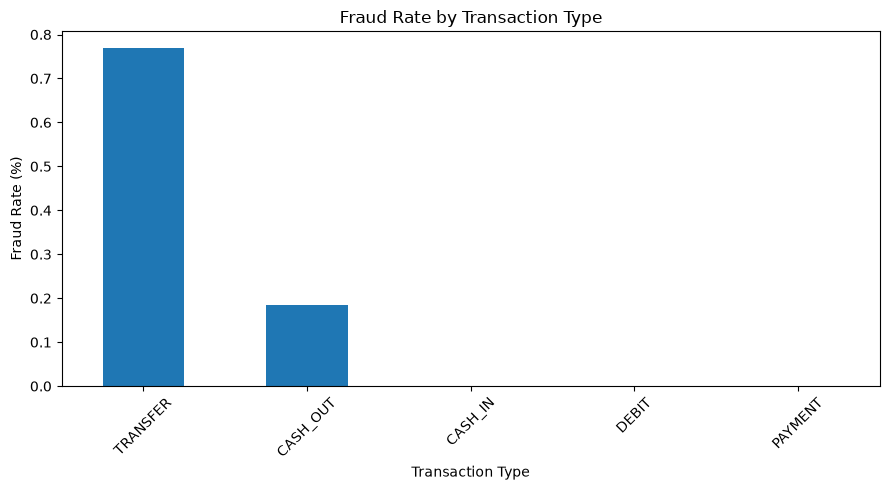

In [45]:
fraud_by_type["fraud_rate_pct"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Fraud Rate by Transaction Type",
    ylabel="Fraud Rate (%)",
    xlabel="Transaction Type"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Key Observations:** <br>
- Cash out has the most fraud cases.
- Transfers have the highest fraud rate.
- This suggests both transaction types deserve attention, but potentially for different reasons. I'd investigate additional characteristics, such as transaction amounts, account balances, and historical activity, before recommending changes to fraud monitoring rules.

In [46]:
# Group the fraud data by "isFraud" and calculate summary statistics for "amount"
amount_summary = (
    fraud_df.groupby("isFraud")["amount"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

amount_summary

,count,mean,median,min,max
isFraud,,,,,
0,6354407,"178,197.04","74,684.72",0.01,"92,445,516.64"
1,8213,"1,467,967.30","441,423.44",0.00,"10,000,000.00"


In [47]:

# Group the fraud data by "type" and "isFraud" and calculate summary statistics for "amount"
amount_by_type = (
    fraud_df[fraud_df["type"].isin(["TRANSFER", "CASH_OUT"])]
    .groupby(["type", "isFraud"])["amount"]
    .agg(["count", "mean", "median", "max"])
    .round(2)
)

amount_by_type

count         mean     median           max
type     isFraud                                               
CASH_OUT 0        2233384   173,917.16 146,946.56  2,847,566.62
         1           4116 1,455,102.59 435,516.90 10,000,000.00
TRANSFER 0         528812   906,229.01 486,521.91 92,445,516.64
         1           4097 1,480,891.67 445,705.76 10,000,000.00

**Key Observations:**<br>
- CASH_OUT: Fraudulent transactions have a median amount almost three times larger than legitimate cash-outs.
- TRANSFER: Fraudulent transfers actually have a slightly lower median amount than legitimate transfers.

In [48]:
# Amount deducted from originating account
fraud_df["origin_balance_change"] = (
    fraud_df["oldbalanceOrg"] - fraud_df["newbalanceOrig"]
)

# Amount added to destination account
fraud_df["dest_balance_change"] = (
    fraud_df["newbalanceDest"] - fraud_df["oldbalanceDest"]
)

In [49]:
# Check whether the originating account balance change matches the transaction amount
fraud_df["origin_balance_mismatch"] = ~np.isclose(
    fraud_df["origin_balance_change"],
    fraud_df["amount"],
    atol=0.01,
    rtol=0
)

pd.crosstab(
    fraud_df["isFraud"],
    fraud_df["origin_balance_mismatch"],
    normalize="index"
) * 100

origin_balance_mismatch,False,True
isFraud,,
0,20.27,79.73
1,99.45,0.55


**Note:**<br>
- 99.45% of fraudulent transactions have an originating balance change that matches the transaction amount.
- Only 20.27% of legitimate transactions show that same consistency.

In [50]:
# Summarize balance mismatch rates by transaction type and fraud status
balance_by_type = (
    fraud_df.groupby(["type", "isFraud"])["origin_balance_mismatch"]
    .agg(
        transactions="count",
        mismatch_rate="mean"
    )
    .reset_index()
)

balance_by_type["mismatch_rate_pct"] = (
    balance_by_type["mismatch_rate"] * 100
)

balance_by_type

,type,isFraud,transactions,mismatch_rate,mismatch_rate_pct
0,CASH_IN,0,1399284,1.00,100.00
1,CASH_OUT,0,2233384,0.89,89.12
2,CASH_OUT,1,4116,0.01,0.58
3,DEBIT,0,41432,0.30,29.79
4,PAYMENT,0,2151495,0.54,53.72
5,TRANSFER,0,528812,0.96,96.20
6,TRANSFER,1,4097,0.01,0.51


In [51]:
# Check the percentage of zero balances by fraud status
fraud_df.groupby("isFraud").agg(
    zero_old_balance_pct=(
        "oldbalanceOrg",
        lambda x: (x == 0).mean() * 100
    ),
    zero_new_balance_pct=(
        "newbalanceOrig",
        lambda x: (x == 0).mean() * 100
    )
).round(2)

,zero_old_balance_pct,zero_new_balance_pct
isFraud,,
0,33.09,56.68
1,0.50,98.05


## Data Preparation for Power BI

In [52]:
dashboard_cols = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "isFraud",
    "isFlaggedFraud",
    "origin_balance_mismatch",
]

dashboard_df = fraud_df[dashboard_cols].copy()

In [53]:
dashboard_df["fraud_status"] = dashboard_df["isFraud"].map({
    0: "Legitimate",
    1: "Fraudulent"
})

In [54]:
dashboard_df["day"] = (dashboard_df["step"] - 1) // 24 + 1

In [55]:
sample_df = dashboard_df[dashboard_df["isFraud"] == 1]

legitimate_df = dashboard_df[
    dashboard_df["isFraud"] == 0
].sample(n=200_000, random_state=42)

dashboard_sample = pd.concat(
    [sample_df, legitimate_df],
    ignore_index=True
).sample(frac=1, random_state=42)

dashboard_sample.shape

(208213, 10)

In [56]:
fraud_summary = (
    dashboard_df.groupby("type")
    .agg(
        total_transactions=("isFraud", "count"),
        fraud_transactions=("isFraud", "sum"),
        total_amount=("amount", "sum"),
        avg_amount=("amount", "mean")
    )
    .reset_index()
)

fraud_summary["fraud_rate_pct"] = (
    fraud_summary["fraud_transactions"]
    / fraud_summary["total_transactions"]
    * 100
)

fraud_summary["legitimate_transactions"] = (
    fraud_summary["total_transactions"]
    - fraud_summary["fraud_transactions"]
)

fraud_summary

,type,total_transactions,fraud_transactions,total_amount,avg_amount,fraud_rate_pct,legitimate_transactions
0,CASH_IN,1399284,0,"236,367,391,912.46","168,920.24",0.00,1399284
1,CASH_OUT,2237500,4116,"394,412,995,224.49","176,273.96",0.18,2233384
2,DEBIT,41432,0,"227,199,221.28","5,483.67",0.00,41432
3,PAYMENT,2151495,0,"28,093,371,138.37","13,057.60",0.00,2151495
4,TRANSFER,532909,4097,"485,291,987,263.17","910,647.01",0.77,528812


In [57]:
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

dashboard_sample.to_csv(
    output_dir / "fraud_transactions_sample.csv",
    index=False
)

fraud_summary.to_csv(
    output_dir / "fraud_summary_by_type.csv",
    index=False
)

print("Power BI datasets exported successfully!")

Power BI datasets exported successfully!
